# Bremsstrahlung Angular Distributions in Silicon

Approximate calculation of photon emission angular distributions for thermal electrons in silicon.

### Key ingredients:
1. **Maxwell-Boltzmann energy distribution** at temperature $T$, using effective mass $m^*$
2. **Characteristic thermal energy**: $E = \frac{3}{2} k_B T$
3. **Bremsstrahlung angular distribution** $d\sigma/d\Omega$:
   - Non-relativistic (dipole): $\propto \sin^2\theta$
   - With relativistic corrections: forward-boosted by $\beta = v/c$

The differential cross-section $d\sigma/d\Omega$ **directly gives** the angular distribution of emitted photons — yes, you get it "for free". For an electron with velocity $\beta c$, the angular distribution of radiated power per solid angle is:

$$\frac{dP}{d\Omega} \propto \frac{\sin^2\theta}{(1 - \beta\cos\theta)^5}$$

In the non-relativistic limit ($\beta \to 0$), this reduces to the familiar $\sin^2\theta$ dipole pattern.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.constants import k as kB, eV, c, m_e

## Silicon effective masses
m_star_e = 0.26 * m_e   # electron conductivity effective mass in Si [kg]
m_star_h = 0.38 * m_e   # hole effective mass (light+heavy avg)

## --- Maxwellian energy distribution ---
def maxwellian_energy(E, T, m_star=m_star_e):
    """
    Maxwell-Boltzmann energy distribution f(E) for 3D
    
    f(E) = 2*pi * (1/(pi*kB*T))^(3/2) * sqrt(E) * exp(-E/(kB*T))
    
    Parameters:
        E: energy [eV]
        T: temperature [K]
        m_star: effective mass [kg] (doesn't appear in energy form)
    Returns:
        f(E) [1/eV] (normalized probability density)
    """
    kT = kB * T / eV  # kT in eV
    return 2 * np.pi * (1 / (np.pi * kT))**1.5 * np.sqrt(E) * np.exp(-E / kT)

## --- Thermal energy shortcuts ---
def thermal_energy(T):
    """Mean thermal energy E = 3/2 kT, returns [eV]"""
    return 1.5 * kB * T / eV

def thermal_velocity(T, m_star=m_star_e):
    """RMS thermal velocity v = sqrt(3 kT / m*), returns [m/s]"""
    return np.sqrt(3 * kB * T / m_star)

def energy_to_beta(E_eV, m_star=m_star_e):
    """Convert kinetic energy [eV] to beta = v/c using m*"""
    v = np.sqrt(2 * E_eV * eV / m_star)
    return v / c

## --- Print some reference values ---
for T in [100, 163, 300]:
    E_th = thermal_energy(T)
    beta = energy_to_beta(E_th, m_star_e)
    v_th = thermal_velocity(T, m_star_e)
    print(f"T = {T:4d} K : E_th = {E_th*1000:.1f} meV,  "
          f"v_th = {v_th:.0f} m/s,  beta = {beta:.2e}")

T =  100 K : E_th = 12.9 meV,  v_th = 132243 m/s,  beta = 4.41e-04
T =  163 K : E_th = 21.1 meV,  v_th = 168836 m/s,  beta = 5.63e-04
T =  300 K : E_th = 38.8 meV,  v_th = 229051 m/s,  beta = 7.64e-04


beta for T = 1000 K is 0.013949235101695406
beta for T = 3000 K is 0.024160783922859662
beta for T = 5000 K is 0.031191437921517125
beta for T = 8000 K is 0.039454394931096974


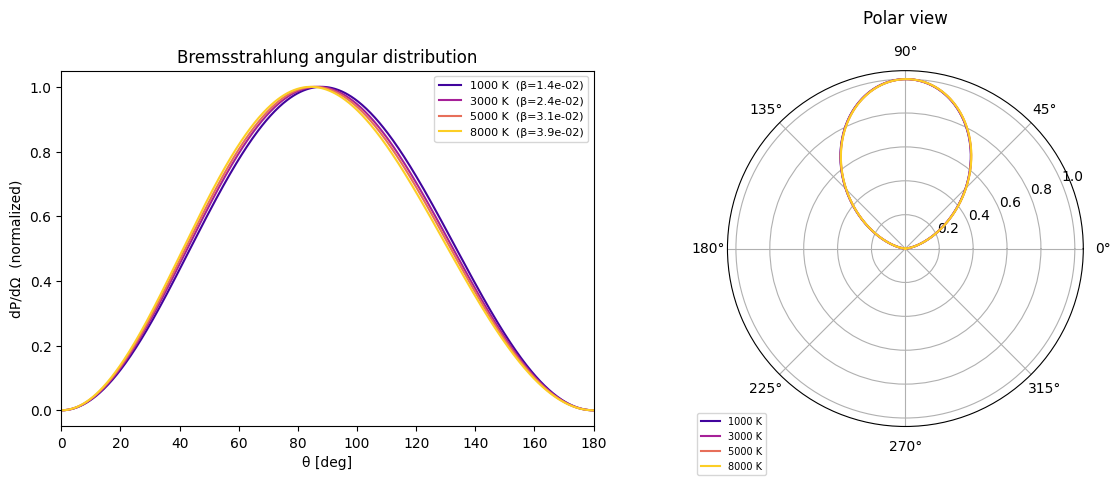

In [6]:
temps = [1000, 3000, 5000, 8000]

## --- Bremsstrahlung angular distribution ---
def dsigma_dOmega(theta, beta):
    """
    Bremsstrahlung angular distribution (relativistic):
    
        dP/dΩ  ∝  sin²θ / (1 - β cosθ)^5
    
    Returns normalized (peak = 1) distribution.
    """
    ct = np.cos(theta)
    st = np.sin(theta)
    raw = st**2 / (1 - beta * ct)**5
    return raw / np.max(raw)


## --- Plot for several temperatures ---
theta = np.linspace(0, np.pi, 500)
theta_deg = np.degrees(theta)

colors = plt.cm.plasma(np.linspace(0.1, 0.9, len(temps)))

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Left panel: Cartesian ---
ax = axes[0]
for T, col in zip(temps, colors):
    E_th = thermal_energy(T)*100
    beta = energy_to_beta(E_th, m_star_e)
    print("beta for T =", T, "K is", beta)
    y = dsigma_dOmega(theta, beta)
    ax.plot(theta_deg, y, color=col, label=f'{T} K  (β={beta:.1e})')

ax.set_xlabel('θ [deg]')
ax.set_ylabel('dP/dΩ  (normalized)')
ax.set_title('Bremsstrahlung angular distribution')
ax.legend(fontsize=8)
ax.set_xlim(0, 180)

# --- Right panel: Polar ---
ax2 = fig.add_subplot(122, projection='polar')
axes[1].remove()

for T, col in zip(temps, colors):
    E_th = thermal_energy(T)
    beta = energy_to_beta(E_th, m_star_e)
    y = dsigma_dOmega(theta, beta)
    ax2.plot(theta, y, color=col, label=f'{T} K')

ax2.set_title('Polar view', pad=15)
ax2.legend(loc='lower left', fontsize=7, bbox_to_anchor=(-0.1, -0.15))

fig.tight_layout()
plt.show()

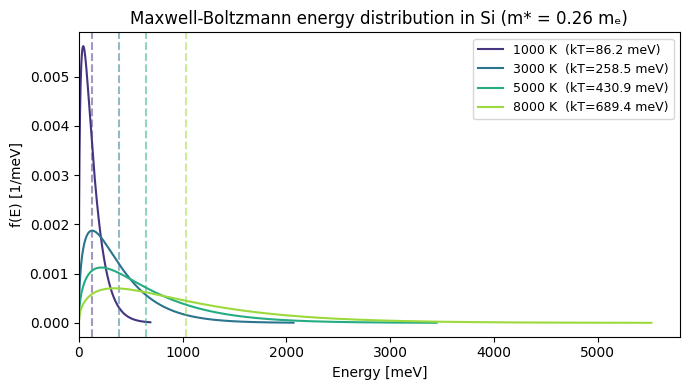

In [3]:
## --- Maxwell-Boltzmann distribution plot ---
fig, ax = plt.subplots(figsize=(7, 4))

colors_mb = plt.cm.viridis(np.linspace(0.15, 0.85, len(temps)))

for T, col in zip(temps, colors_mb):
    kT = kB * T / eV  # eV
    E = np.linspace(0, 8 * kT, 500)
    fE = maxwellian_energy(E, T)
    ax.plot(E * 1000, fE / 1000, color=col, label=f'{T} K  (kT={kT*1000:.1f} meV)')
    # mark E_th = 3/2 kT
    E_th = thermal_energy(T)
    ax.axvline(E_th * 1000, color=col, ls='--', alpha=0.5)

ax.set_xlabel('Energy [meV]')
ax.set_ylabel('f(E) [1/meV]')
ax.set_title('Maxwell-Boltzmann energy distribution in Si (m* = 0.26 mₑ)')
ax.legend(fontsize=9)
ax.set_xlim(0, None)
fig.tight_layout()
plt.show()

## Coulomb-screened scattering → Bremsstrahlung emission

### Setup
An electron with momentum $\hbar k$ scatters off a screened Coulomb potential. The momentum transfer is $q^2 = 2k^2(1 - \cos\theta_s)$, giving the **Rutherford + screening** cross-section:

$$\frac{d\sigma}{d\Omega} \propto \frac{1}{\left[2k^2(1 - \cos\theta_s) + k_s^2\right]^2}$$

where $k_s$ is the Thomas-Fermi (or Debye) screening wavevector.

### From scattering to radiation
At each scattering angle $\theta_s$, the electron undergoes a velocity change $\Delta \vec{v}$. For elastic scattering off a heavy nucleus, $|\vec{v}|$ is conserved but the direction changes by $\theta_s$:

$$|\Delta v| = 2v \sin(\theta_s / 2)$$

The **radiated power** from an accelerated charge goes as $|\Delta v|^2$, and the **angular pattern of the emitted photon** (at angle $\theta_\gamma$ from $\Delta\vec{v}$) is the dipole:

$$\frac{dP}{d\Omega_\gamma} \propto \sin^2\theta_\gamma$$

### Combining: net photon angular distribution
Weight the dipole emission by the scattering probability at each $\theta_s$ and the radiation strength $|\Delta v|^2$:

$$\frac{dP_{\rm total}}{d\Omega_\gamma} \propto \int d\Omega_s \; \frac{d\sigma}{d\Omega_s} \; |\Delta v(\theta_s)|^2 \; \sin^2\theta_\gamma(\theta_s, \phi_s, \theta_\gamma)$$

This requires a 2D integral (over $\theta_s, \phi_s$) for each photon observation angle $\theta_\gamma$.

In [7]:
from scipy.constants import hbar, epsilon_0, e as e_charge
from scipy.integrate import simpson

## ============================================================
##  Screened Coulomb scattering cross-section
## ============================================================

def dsigma_coulomb(theta_s, k, k_s):
    """
    Screened Coulomb (Rutherford) differential cross-section.
    
    dσ/dΩ ∝ 1 / [2k²(1 - cosθ_s) + k_s²]²
    
    Parameters:
        theta_s : scattering angle [rad]
        k       : electron wavevector [1/m]
        k_s     : screening wavevector [1/m]
    Returns:
        unnormalized dσ/dΩ
    """
    q2 = 2 * k**2 * (1 - np.cos(theta_s))
    return 1.0 / (q2 + k_s**2)**2


def delta_v(v, theta_s):
    """
    Magnitude of velocity change for elastic scattering:
    |Δv| = 2v sin(θ_s/2)
    """
    return 2 * v * np.sin(theta_s / 2)


## ============================================================
##  Compute net photon angular distribution
## ============================================================
##  For each photon observation angle θ_γ (measured from the 
##  incoming electron direction ẑ), integrate over all scattering
##  angles (θ_s, φ_s).
##
##  The acceleration Δv̂ lies in the scattering plane. For a 
##  scattering event (θ_s, φ_s), the unit vector along Δv is:
##
##      Δv̂ = ( sin(θ_s/2) cos(φ_s),
##              sin(θ_s/2) sin(φ_s),
##             -[1 - cos(θ_s/2)] ... )  — but we only need the 
##  angle between Δv̂ and the photon direction n̂_γ.
##
##  Photon direction (azimuthally symmetric → pick φ_γ = 0):
##      n̂_γ = (sinθ_γ, 0, cosθ_γ)
##
##  The Δv direction bisects the incoming (ẑ) and outgoing 
##  directions. The unit Δv̂ (pointing along the momentum 
##  transfer, perpendicular to the bisector):
##      Δv̂ = ( cos(θ_s/2) cos(φ_s),
##              cos(θ_s/2) sin(φ_s),
##             -sin(θ_s/2) )
##
##  cos(angle between Δv̂ and n̂_γ):
##      cos α = sinθ_γ cos(θ_s/2) cos(φ_s) - cosθ_γ sin(θ_s/2)
##
##  Dipole radiation pattern: sin²α = 1 - cos²α
## ============================================================

def photon_angular_distribution(theta_gamma_arr, k, k_s, v,
                                 N_theta_s=500, N_phi_s=200):
    """
    Compute the net bremsstrahlung photon angular distribution
    by integrating over screened Coulomb scattering angles.
    
    Parameters:
        theta_gamma_arr : array of photon observation angles [rad]
        k    : electron wavevector [1/m]
        k_s  : screening wavevector [1/m]
        v    : electron speed [m/s]
        N_theta_s, N_phi_s : integration grid sizes
    Returns:
        dP/dΩ_γ (unnormalized) at each θ_γ
    """
    theta_s = np.linspace(1e-6, np.pi, N_theta_s)
    phi_s   = np.linspace(0, 2*np.pi, N_phi_s)
    
    # Precompute scattering-angle-dependent quantities
    dσ   = dsigma_coulomb(theta_s, k, k_s)          # (N_θs,)
    dv2  = delta_v(v, theta_s)**2                     # (N_θs,)
    weight = dσ * dv2 * np.sin(theta_s)              # Jacobian sinθ_s
    
    cos_half = np.cos(theta_s / 2)  # (N_θs,)
    sin_half = np.sin(theta_s / 2)  # (N_θs,)
    
    result = np.zeros_like(theta_gamma_arr)
    
    for i, tg in enumerate(theta_gamma_arr):
        sin_tg = np.sin(tg)
        cos_tg = np.cos(tg)
        
        # Integrate over φ_s analytically where possible:
        # <sin²α>_φ = 1 - <cos²α>_φ
        # cosα = sin_tg * cos_half * cos(φ_s) - cos_tg * sin_half
        #
        # <cos²α>_φ = sin²_tg * cos²_half * <cos²φ> 
        #           - 2 sin_tg cos_tg * cos_half * sin_half * <cosφ>
        #           + cos²_tg * sin²_half
        # <cos²φ> = 1/2,  <cosφ> = 0
        
        cos2_alpha_avg = (0.5 * sin_tg**2 * cos_half**2 
                          + cos_tg**2 * sin_half**2)
        sin2_alpha_avg = 1 - cos2_alpha_avg
        
        # Integrand over θ_s (φ_s already integrated analytically)
        integrand = weight * sin2_alpha_avg * 2 * np.pi  # ×2π from φ_s
        
        result[i] = simpson(integrand, x=theta_s)
    
    return result


## ============================================================
##  Physical parameters
## ============================================================

def electron_k(E_eV, m_star=m_star_e):
    """Electron wavevector k = sqrt(2 m* E) / hbar, returns [1/m]"""
    return np.sqrt(2 * m_star * E_eV * eV) / hbar

def thomas_fermi_ks(n_e=1e16 * 1e6):
    """
    Thomas-Fermi screening wavevector (degenerate limit).
    k_s² = e² n_e / (ε₀ E_F)  — but for classical Si at low doping,
    use Debye: k_s² = e² n / (ε₀ kB T).
    
    For simplicity, take k_s as a parameter. 
    Typical: k_s ~ 1e8 - 1e9 /m for doped Si.
    Default: n_e = 1e16 /cm³, T=300K → k_D ~ 4e8 /m
    """
    # Debye screening at 300K
    T_ref = 300
    eps_Si = 11.7 * epsilon_0
    return np.sqrt(e_charge**2 * n_e / (eps_Si * kB * T_ref))


## --- Print reference values ---
for E_eV in [0.05, 0.1, 0.5, 1.0]:
    k_val = electron_k(E_eV)
    print(f"E = {E_eV:.2f} eV :  k = {k_val:.2e} /m")

k_s_ref = thomas_fermi_ks(1e16 * 1e6)
print(f"\nDebye screening k_s = {k_s_ref:.2e} /m  (n = 1e16 /cm³, T=300K)")
print(f"Ratio k_s/k(0.05eV) = {k_s_ref/electron_k(0.05):.3f}")
print(f"Ratio k_s/k(1.0 eV) = {k_s_ref/electron_k(1.0):.3f}")

E = 0.05 eV :  k = 5.84e+08 /m
E = 0.10 eV :  k = 8.26e+08 /m
E = 0.50 eV :  k = 1.85e+09 /m
E = 1.00 eV :  k = 2.61e+09 /m

Debye screening k_s = 2.45e+07 /m  (n = 1e16 /cm³, T=300K)
Ratio k_s/k(0.05eV) = 0.042
Ratio k_s/k(1.0 eV) = 0.009


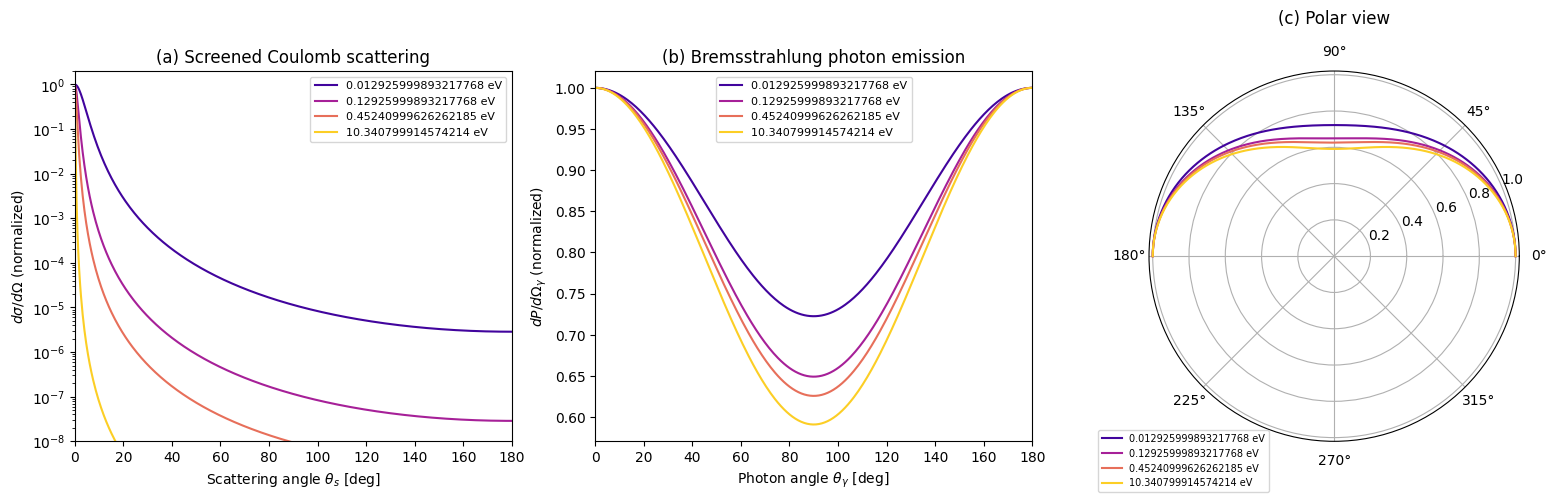

In [10]:
## ============================================================
##  Plot: Coulomb-screened bremsstrahlung angular distribution
##        for fixed electron energies
## ============================================================

theta_gamma = np.linspace(1e-4, np.pi, 300)
theta_gamma_deg = np.degrees(theta_gamma)

energies_temp = np.array([100, 1000, 3500, 80000])
# energies_eV = [0.025, 0.05, 0.1, 0.5, 1.0]
energies_eV = thermal_energy(energies_temp)  # Convert T to E_th for plotting

k_s = thomas_fermi_ks(1e16 * 1e6)   # Debye screening, n=1e16/cm³

colors_c = plt.cm.plasma(np.linspace(0.1, 0.9, len(energies_eV)))

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

## --- (a) Screened Coulomb dσ/dΩ vs scattering angle ---
ax0 = axes[0]
theta_s_plot = np.linspace(1e-4, np.pi, 500)
for E, col in zip(energies_eV, colors_c):
    k_val = electron_k(E)
    ds = dsigma_coulomb(theta_s_plot, k_val, k_s)
    ds /= np.max(ds)
    ax0.semilogy(np.degrees(theta_s_plot), ds, color=col, label=f'{E} eV')
ax0.set_xlabel(r'Scattering angle $\theta_s$ [deg]')
ax0.set_ylabel(r'$d\sigma/d\Omega$ (normalized)')
ax0.set_title('(a) Screened Coulomb scattering')
ax0.legend(fontsize=8)
ax0.set_xlim(0, 180)
ax0.set_ylim(1e-8, 2)

## --- (b) Net photon angular distribution (Cartesian) ---
ax1 = axes[1]
for E, col in zip(energies_eV, colors_c):
    k_val = electron_k(E)
    v_val = hbar * k_val / m_star_e
    dP = photon_angular_distribution(theta_gamma, k_val, k_s, v_val)
    dP /= np.max(dP)
    ax1.plot(theta_gamma_deg, dP, color=col, label=f'{E} eV')

ax1.set_xlabel(r'Photon angle $\theta_\gamma$ [deg]')
ax1.set_ylabel(r'$dP/d\Omega_\gamma$ (normalized)')
ax1.set_title('(b) Bremsstrahlung photon emission')
ax1.legend(fontsize=8)
ax1.set_xlim(0, 180)

## --- (c) Polar view ---
ax2 = fig.add_subplot(133, projection='polar')
axes[2].remove()
for E, col in zip(energies_eV, colors_c):
    k_val = electron_k(E)
    v_val = hbar * k_val / m_star_e
    dP = photon_angular_distribution(theta_gamma, k_val, k_s, v_val)
    dP /= np.max(dP)
    ax2.plot(theta_gamma, dP, color=col, label=f'{E} eV')
ax2.set_title('(c) Polar view', pad=15)
ax2.legend(loc='lower left', fontsize=7, bbox_to_anchor=(-0.15, -0.15))

fig.tight_layout()
plt.show()